# PathSnap: Dataset Exploration

**Purpose:** reproducible, structured audit of the raw GPS and road-network data before implementing map matching. Run in local Jupyter. DATA_ROOT is set to D:\Projects\PathSnap_ML_Hackathon, which should contain train and student_test. This notebook inspects files and writes audit tables/plots; it does not train or tune models.

## Requirements from the project documents
- Expected partitions: 80 training, 10 student-testing, 10 evaluator-testing trips. The notebook reports actual counts and does not assume the provided folder tree matches this exactly.
- '.track': headerless, whitespace-separated longitude, latitude, timestamp in seconds. Typical interval is 1 second, but gaps/duplicates must be measured.
- '.nodes': headerless longitude, latitude; row position is the zero-based node ID.
- '.arcs': headerless from_node_id, to_node_id; row position is the zero-based arc ID.
- '.route': headerless ordered arc IDs, when supplied. Check arc references before treating it as ground truth.
- Do not use evaluator-testing data or labels for model fitting, feature selection, tuning, or route reconstruction decisions. Keep reference routes separate from prediction inputs.

**Sample provided in this conversation:** trip '00000001' has 1,315 track rows (40,975 bytes), 88,809 node rows (1,687,371 bytes), 165,790 arc rows (1,948,474 bytes), and 525 route rows (3,119 bytes). A preliminary audit found no invalid GPS coordinates or non-increasing timestamps; the median interval is 1 second, with one gap over 5 seconds (maximum 16 seconds). The track bounds are 8.570524-8.647860 longitude and 49.844053-50.211882 latitude, with about 50.19 km of summed GPS steps. Its graph has 175 weakly connected components, a largest component of 86,854/88,809 nodes (97.8%), and no isolated nodes or invalid arc endpoints. The sample reference route has 525 valid arc IDs and no broken consecutive arc joins. These findings describe one sample only, not the full dataset.

> Before interpreting connectivity, confirm whether each trip folder contains a complete network copy or a trip-specific subgraph. This notebook detects exact file duplicates by SHA-256, but does not silently collapse trip records.

In [1]:
from pathlib import Path
import os, re, hashlib, json, math, warnings
import numpy as np
import pandas as pd
from IPython.display import display

# Local Jupyter setup: DATA_ROOT is the parent folder containing train/ and student_test/
DATA_ROOT = Path(r'D:\Projects\PathSnap_ML_Hackathon')
OUTPUT_DIR = DATA_ROOT / 'exploration_outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
EXPECTED_EXTS = ['.track', '.nodes', '.arcs', '.route']
print('DATA_ROOT exists:', DATA_ROOT.exists(), '| path:', DATA_ROOT)
if DATA_ROOT.exists():
    print('Top-level entries:', [p.name for p in list(DATA_ROOT.iterdir())[:30]])

DATA_ROOT exists: True | path: D:\Projects\PathSnap_ML_Hackathon
Top-level entries: ['.git', 'datasets', 'exploration_outputs', 'PathSnap_Dataset_Exploration.ipynb', 'student_test', 'train']


## 1. Discover partitions and trips

The scanner treats a directory containing a '.track' file as a trip folder. It infers a partition from the nearest ancestor directory name containing train/training, student, evaluator/test, or validation keywords. Review the inferred labels; if your folder names differ, edit 'PARTITION_OVERRIDES' in the next cell. The expected dataset tree will be confirmed against your full tree when available.

In [2]:
PARTITION_OVERRIDES = {}  # e.g. {'00000001': 'training'}; keys are trip folder names

def infer_partition(path, root):
    rel_parts = path.relative_to(root).parts[:-1]
    for part in reversed(rel_parts):
        s = part.lower().replace('-', '_').replace(' ', '_')
        if any(k in s for k in ('evaluator', 'evaluation', 'final_test')): return 'evaluator_testing'
        if any(k in s for k in ('student', 'validation', 'dev')): return 'student_testing'
        if any(k in s for k in ('train', 'training')): return 'training'
    return 'unclassified'

trip_dirs = sorted({p.parent for ext in EXPECTED_EXTS for p in DATA_ROOT.rglob('*'+ext)}) if DATA_ROOT.exists() else []
trip_dirs = [p for p in trip_dirs if p.is_dir()]
print('Trip folders found:', len(trip_dirs))
print('Partition inference counts:')
partition_by_trip = {d.name: PARTITION_OVERRIDES.get(d.name, infer_partition(d, DATA_ROOT)) for d in trip_dirs}
display(pd.Series(partition_by_trip).value_counts().rename_axis('partition').to_frame('trip_count'))
display(pd.DataFrame({'trip_id':[d.name for d in trip_dirs], 'folder':[str(d) for d in trip_dirs], 'partition':[partition_by_trip[d.name] for d in trip_dirs]}).head(20))

Trip folders found: 90
Partition inference counts:


,trip_count
partition,
training,80
student_testing,10


,trip_id,folder,partition
0,00000000,D:\Projects\PathSnap_ML_Hackathon\student_test...,student_testing
1,00000007,D:\Projects\PathSnap_ML_Hackathon\student_test...,student_testing
2,00000009,D:\Projects\PathSnap_ML_Hackathon\student_test...,student_testing
3,00000040,D:\Projects\PathSnap_ML_Hackathon\student_test...,student_testing
4,00000052,D:\Projects\PathSnap_ML_Hackathon\student_test...,student_testing
5,00000056,D:\Projects\PathSnap_ML_Hackathon\student_test...,student_testing
6,00000065,D:\Projects\PathSnap_ML_Hackathon\student_test...,student_testing
7,00000076,D:\Projects\PathSnap_ML_Hackathon\student_test...,student_testing
8,00000077,D:\Projects\PathSnap_ML_Hackathon\student_test...,student_testing
9,00000091,D:\Projects\PathSnap_ML_Hackathon\student_test...,student_testing


## 2. File inventory, schemas, and per-trip GPS quality

All raw files are parsed as headerless whitespace-separated numeric columns. The code reports missing files, sizes, row/column counts, data types, malformed rows, missing/nonfinite values, coordinate plausibility, timestamp order, duplicate times, time gaps, trajectory extent, and haversine path length. Gap flags use transparent exploratory thresholds (greater than 5 seconds); keep the raw distributions when deciding downstream handling.

In [3]:
SCHEMAS = {'.track':['longitude','latitude','timestamp_s'], '.nodes':['longitude','latitude'], '.arcs':['from_node_id','to_node_id'], '.route':['arc_id']}

def read_numeric(path, ext):
    # Read rows independently to retain/report malformed lines without shifting columns.
    expected = len(SCHEMAS[ext]); rows=[]; bad=[]
    with open(path, 'r', encoding='utf-8', errors='replace') as f:
        for line_no, line in enumerate(f, 1):
            if not line.strip(): continue
            parts = line.split()
            try:
                if len(parts) != expected: raise ValueError(f'expected {expected} columns, got {len(parts)}')
                rows.append([float(x) for x in parts])
            except Exception as e: bad.append((line_no, str(e)))
    df = pd.DataFrame(rows, columns=SCHEMAS[ext])
    return df, bad

def haversine_m(lon1,lat1,lon2,lat2):
    r=6371008.8; p1=np.radians(lat1); p2=np.radians(lat2)
    dp=np.radians(lat2-lat1); dl=np.radians(lon2-lon1)
    a=np.sin(dp/2)**2+np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2
    return 2*r*np.arcsin(np.sqrt(np.clip(a,0,1)))

file_rows=[]; track_rows=[]; parse_issues=[]; parsed={}
for folder in trip_dirs:
    trip=folder.name
    for ext in EXPECTED_EXTS:
        matches=list(folder.glob('*'+ext))
        if not matches:
            file_rows.append({'trip_id':trip,'partition':partition_by_trip[trip],'extension':ext,'present':False,'file':None,'bytes':np.nan,'rows':np.nan,'columns':np.nan,'dtypes':None,'malformed_rows':np.nan})
            continue
        for path in matches:
            df,bad=read_numeric(path,ext); parsed[(trip,ext)]=df
            file_rows.append({'trip_id':trip,'partition':partition_by_trip[trip],'extension':ext,'present':True,'file':path.name,'bytes':path.stat().st_size,'rows':len(df),'columns':len(df.columns),'dtypes':', '.join(f'{c}:{t}' for c,t in df.dtypes.items()),'malformed_rows':len(bad)})
            for line_no,err in bad[:100]: parse_issues.append({'trip_id':trip,'file':path.name,'line':line_no,'issue':err})
    t=parsed.get((trip,'.track'))
    if t is None or t.empty: continue
    finite=np.isfinite(t[['longitude','latitude','timestamp_s']]).all(axis=1)
    coord_ok=t.longitude.between(-180,180)&t.latitude.between(-90,90)
    dt=t.timestamp_s.diff(); gaps=dt[dt>0]
    step=haversine_m(t.longitude.shift(),t.latitude.shift(),t.longitude,t.latitude)
    track_rows.append({'trip_id':trip,'partition':partition_by_trip[trip],'n_gps':len(t),'missing_or_nonfinite_rows':int((~finite).sum()),'invalid_coordinate_rows':int((~coord_ok).sum()),'timestamp_non_increasing':int((dt<=0).sum()),'duplicate_timestamp_rows':int((dt==0).sum()),'negative_time_steps':int((dt<0).sum()),'time_gap_gt_5s':int((dt>5).sum()),'max_positive_gap_s':gaps.max() if len(gaps) else np.nan,'median_positive_gap_s':gaps.median() if len(gaps) else np.nan,'timestamp_start_s':t.timestamp_s.min(),'timestamp_end_s':t.timestamp_s.max(),'lon_min':t.longitude.min(),'lon_max':t.longitude.max(),'lat_min':t.latitude.min(),'lat_max':t.latitude.max(),'path_length_km':float(step.sum(skipna=True)/1000),'max_step_km':float(step.max(skipna=True)/1000)})

file_inventory=pd.DataFrame(file_rows); gps_summary=pd.DataFrame(track_rows); parse_issues=pd.DataFrame(parse_issues)
print('Partition trip counts (all discovered folders):'); display(pd.Series(partition_by_trip).value_counts().rename_axis('partition').to_frame('trips'))
print('File inventory:'); display(file_inventory.head(20))
print('GPS summary (sorted by largest gap):'); display(gps_summary.sort_values('max_positive_gap_s',ascending=False).head(20))
print('Malformed lines:',len(parse_issues)); display(parse_issues.head())

Partition trip counts (all discovered folders):


,trips
partition,
training,80
student_testing,10


File inventory:


,trip_id,partition,extension,present,file,bytes,rows,columns,dtypes,malformed_rows
0,00000000,student_testing,.track,True,00000000.track,81492,2503,3,"longitude:float64, latitude:float64, timestamp...",0
1,00000000,student_testing,.nodes,True,00000000.nodes,170840,8542,2,"longitude:float64, latitude:float64",0
2,00000000,student_testing,.arcs,True,00000000.arcs,176989,18196,2,"from_node_id:float64, to_node_id:float64",0
3,00000000,student_testing,.route,True,00000000.route,881,179,1,arc_id:float64,0
4,00000007,student_testing,.track,True,00000007.track,43575,1354,3,"longitude:float64, latitude:float64, timestamp...",0
5,00000007,student_testing,.nodes,True,00000007.nodes,41220,2061,2,"longitude:float64, latitude:float64",0
6,00000007,student_testing,.arcs,True,00000007.arcs,38998,4369,2,"from_node_id:float64, to_node_id:float64",0
7,00000007,student_testing,.route,True,00000007.route,486,123,1,arc_id:float64,0
8,00000009,student_testing,.track,True,00000009.track,33513,1049,3,"longitude:float64, latitude:float64, timestamp...",0
9,00000009,student_testing,.nodes,True,00000009.nodes,134900,6745,2,"longitude:float64, latitude:float64",0


GPS summary (sorted by largest gap):


,trip_id,partition,n_gps,missing_or_nonfinite_rows,invalid_coordinate_rows,timestamp_non_increasing,duplicate_timestamp_rows,negative_time_steps,time_gap_gt_5s,max_positive_gap_s,median_positive_gap_s,timestamp_start_s,timestamp_end_s,lon_min,lon_max,lat_min,lat_max,path_length_km,max_step_km
82,00000090,training,536,0,0,0,0,0,20,153064.0,1.0,4.0,154034.000,10.417463,10.465737,51.618723,51.626741,8.579127,0.035624
71,00000078,training,2909,0,0,0,0,0,124,52810.0,1.0,3.0,57839.000,3.586272,4.196450,44.226923,44.367360,79.484722,0.215209
65,00000069,training,2067,0,0,0,0,0,2,2658.0,1.0,1.0,5559.000,-52.804119,-52.745174,47.523928,47.564999,25.742235,0.066161
26,00000021,training,15783,0,0,0,0,0,2,2161.0,1.0,2.0,18607.000,106.377397,106.733064,15.345165,15.445932,128.789175,0.045950
18,00000011,training,2828,0,0,0,0,0,1,909.0,1.0,1.0,3736.000,59.647057,60.016866,56.041788,56.067535,54.972402,0.050323
44,00000042,training,7739,0,0,0,0,0,45,670.0,1.0,1.0,12378.000,123.911786,124.050254,10.335168,10.881855,98.179548,0.058395
74,00000081,training,3224,0,0,0,0,0,129,536.0,1.0,3.0,8484.000,-82.190594,-82.111754,26.444143,26.510902,38.791240,0.109240
28,00000024,training,801,0,0,0,0,0,4,458.0,1.0,1.0,1542.000,8.547344,8.618828,49.148019,49.359556,26.676186,0.065739
46,00000044,training,546,0,0,0,0,0,2,341.0,1.0,1.0,981.000,39.237245,39.275171,51.610279,51.657122,7.932692,0.036207
77,00000084,training,16031,0,0,0,0,0,4,312.0,1.0,1.0,16525.000,-87.097364,-86.741408,34.710965,34.807972,136.807446,0.049225


Malformed lines: 0


""


## 3. Network structure, connectivity, and route references

Node IDs and arc IDs are assumed to be zero-based row positions, per the dataset description. For each folder, the audit checks arc endpoint validity, self-loops, duplicate directed arcs, isolated nodes, weakly connected components, and route arc-ID validity. A directed graph is used for arc validity and reachability; weak components are used for a robust overview of undirected connectivity. Large graphs are processed with SciPy sparse matrices. A reference route is only checked for existence and valid IDs here; it is not assumed to be an independently verified physical ground truth.

In [4]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
network_rows=[]; route_rows=[]
for folder in trip_dirs:
    trip=folder.name; nodes=parsed.get((trip,'.nodes')); arcs=parsed.get((trip,'.arcs')); route=parsed.get((trip,'.route'))
    if nodes is None or arcs is None: continue
    n=len(nodes); a=len(arcs)
    u=arcs.from_node_id.to_numpy(); v=arcs.to_node_id.to_numpy()
    integ=np.isfinite(u)&np.isfinite(v)&(u==np.floor(u))&(v==np.floor(v))
    endpoint_ok=integ&(u>=0)&(u<n)&(v>=0)&(v<n)
    bad=int((~endpoint_ok).sum())
    valid_u=u[endpoint_ok].astype(int); valid_v=v[endpoint_ok].astype(int)
    counts=np.bincount(np.r_[valid_u,valid_v], minlength=n) if n else np.array([])
    isolated=int((counts==0).sum()) if n else 0
    if n and len(valid_u):
        graph=coo_matrix((np.ones(len(valid_u)*2), (np.r_[valid_u,valid_v],np.r_[valid_v,valid_u])),shape=(n,n)).tocsr()
        ncomp, labels=connected_components(graph,directed=False,return_labels=True)
        comp_sizes=np.bincount(labels)
        largest=int(comp_sizes.max()) if len(comp_sizes) else 0
    else: ncomp=n; largest=1 if n else 0
    edge_pairs=pd.DataFrame({'u':valid_u,'v':valid_v})
    duplicate_directed=int(edge_pairs.duplicated().sum())
    self_loops=int((valid_u==valid_v).sum())
    network_rows.append({'trip_id':trip,'partition':partition_by_trip[trip],'nodes':n,'arcs':a,'invalid_arc_endpoints':bad,'isolated_nodes':isolated,'weak_component_count':int(ncomp),'largest_component_nodes':largest,'largest_component_fraction':largest/n if n else np.nan,'duplicate_directed_arcs':duplicate_directed,'self_loops':self_loops,'node_lon_min':nodes.longitude.min(),'node_lon_max':nodes.longitude.max(),'node_lat_min':nodes.latitude.min(),'node_lat_max':nodes.latitude.max()})
    if route is None:
        route_rows.append({'trip_id':trip,'partition':partition_by_trip[trip],'route_present':False,'route_arcs':np.nan,'invalid_route_arc_ids':np.nan,'route_has_consecutive_disconnected_arcs':np.nan})
    else:
        ids=route.arc_id.to_numpy(); ok=np.isfinite(ids)&(ids==np.floor(ids))&(ids>=0)&(ids<a)
        # Compare endpoint continuity for successive valid route arc indices.
        seq=ids[ok].astype(int); disconnected=0
        for x,y in zip(seq[:-1],seq[1:]):
            if int(arcs.iloc[x,1]) != int(arcs.iloc[y,0]): disconnected+=1
        route_rows.append({'trip_id':trip,'partition':partition_by_trip[trip],'route_present':True,'route_arcs':len(route),'invalid_route_arc_ids':int((~ok).sum()),'route_has_consecutive_disconnected_arcs':disconnected})
network_summary=pd.DataFrame(network_rows); route_summary=pd.DataFrame(route_rows)
print('Network summary:'); display(network_summary.head(20))
print('Route summary:'); display(route_summary.head(20))
print('Network variability by partition:'); display(network_summary.groupby('partition')[['nodes','arcs','isolated_nodes','weak_component_count','largest_component_fraction']].agg(['min','median','max']))

Network summary:


,trip_id,partition,nodes,arcs,invalid_arc_endpoints,isolated_nodes,weak_component_count,largest_component_nodes,largest_component_fraction,duplicate_directed_arcs,self_loops,node_lon_min,node_lon_max,node_lat_min,node_lat_max
0,00000000,student_testing,8542,18196,0,0,100,7466,0.874034,6,0,54.238593,54.973630,56.070572,56.264534
1,00000007,student_testing,2061,4369,0,0,6,1999,0.969918,0,0,77.112093,77.280906,43.378763,43.506274
2,00000009,student_testing,6745,13106,0,0,8,6538,0.969311,62,0,13.622095,13.716908,42.635672,42.672403
3,00000040,student_testing,12945,27026,0,0,15,12810,0.989571,0,0,61.059539,61.302585,55.165338,55.426294
4,00000052,student_testing,1770,3577,0,0,7,1681,0.949718,2,0,35.848118,35.906404,56.785271,56.837409
5,00000056,student_testing,14759,27631,0,0,24,14427,0.977505,22,0,-93.434290,-93.338509,44.826035,44.883353
6,00000065,student_testing,6448,13184,0,0,5,6388,0.990695,4,0,49.253289,49.339762,53.502682,53.548904
7,00000076,student_testing,26635,56027,0,0,40,25629,0.962230,29,0,43.951486,44.043704,56.230451,56.338713
8,00000077,student_testing,4424,9622,0,0,11,4297,0.971293,0,0,50.779109,50.851261,61.629854,61.709158
9,00000091,student_testing,6360,12303,0,0,11,6264,0.984906,3,2,2.401240,2.453548,47.043230,47.109674


Route summary:


,trip_id,partition,route_present,route_arcs,invalid_route_arc_ids,route_has_consecutive_disconnected_arcs
0,00000000,student_testing,True,179,0,0
1,00000007,student_testing,True,123,0,0
2,00000009,student_testing,True,429,0,0
3,00000040,student_testing,True,309,0,0
4,00000052,student_testing,True,95,0,0
5,00000056,student_testing,True,1323,0,0
6,00000065,student_testing,True,145,0,0
7,00000076,student_testing,True,374,0,1
8,00000077,student_testing,True,268,0,0
9,00000091,student_testing,True,232,0,0


Network variability by partition:


nodes                  arcs                  isolated_nodes  \
                  min  median     max   min   median     max            min   
partition                                                                     
student_testing  1770  6596.5   26635  3577  13145.0   56027              0   
training          299  9608.0  155003   649  19526.5  307392              0   

                           weak_component_count              \
                median max                  min median  max   
partition                                                     
student_testing    0.0   0                    5   11.0  100   
training           0.0   0                    1   20.0  421   

                largest_component_fraction                      
                                       min    median       max  
partition                                                       
student_testing                   0.874034  0.970605  0.990695  
training                          0.692797  0.981066  1.000000

## 4. Shared-file checks, plots, and saved outputs

Identical SHA-256 hashes help determine whether network files are duplicated across trip folders. File size or matching counts alone do not prove network identity. The plots below show the observed GPS cloud and gap distribution. CSV outputs are written under the local exploration_outputs folder; they are evidence for exploration and do not modify source data.

Most repeated exact network files:


,extension,sha256,trip_copies,bytes
0,.arcs,00762d8cc20cc2c7c07aa7d04b4e6622c33fa36712c1b4...,1,277927
1,.arcs,00e5d05a51b70574dea8ce81c63e8b481027f4c06d3e1c...,1,823242
2,.arcs,030d978396b18bcf42918d8586295e576d115c769bb55d...,1,50518
3,.arcs,03e8a181b3b01d746050aa6f0a814f03e73cdb5248b110...,1,30902
4,.arcs,0631b69d42d89f49dc8e74fde4724c18820fa978265c98...,1,3171304
5,.arcs,076045348b89bda5236ab9af6b770a1ac0bb4bb79469c4...,1,458962
6,.arcs,0a75e472d7ae0b89400baad56de82a556572621bf1a80c...,1,49400
7,.arcs,0acf633e9388c031fb6519721ea04bef7f3677304c32f4...,1,147040
8,.arcs,0ea32371062711791e62a4f0517879647cf2f635971ec9...,1,1772302
9,.arcs,1187c66e784ec16a71ea5fe2b85eb34c3ac1d7fcc7822e...,1,534894


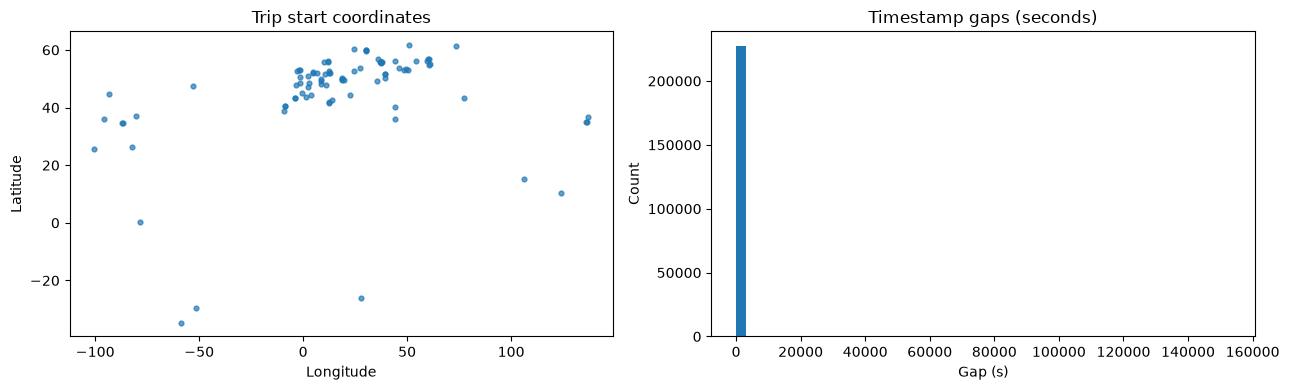

Wrote: D:\Projects\PathSnap_ML_Hackathon\exploration_outputs\file_inventory.csv D:\Projects\PathSnap_ML_Hackathon\exploration_outputs\gps_summary.csv D:\Projects\PathSnap_ML_Hackathon\exploration_outputs\network_summary.csv D:\Projects\PathSnap_ML_Hackathon\exploration_outputs\route_summary.csv D:\Projects\PathSnap_ML_Hackathon\exploration_outputs\parse_issues.csv D:\Projects\PathSnap_ML_Hackathon\exploration_outputs\network_hashes.csv


In [5]:
hash_rows=[]
for folder in trip_dirs:
    for ext in ('.nodes','.arcs'):
        for path in folder.glob('*'+ext):
            h=hashlib.sha256(path.read_bytes()).hexdigest()
            hash_rows.append({'trip_id':folder.name,'partition':partition_by_trip[folder.name],'extension':ext,'sha256':h,'bytes':path.stat().st_size})
network_hashes=pd.DataFrame(hash_rows)
if not network_hashes.empty:
    hash_counts=network_hashes.groupby(['extension','sha256']).agg(trip_copies=('trip_id','nunique'),bytes=('bytes','first')).reset_index().sort_values('trip_copies',ascending=False)
    print('Most repeated exact network files:'); display(hash_counts.head(20))

import matplotlib.pyplot as plt
fig,ax=plt.subplots(1,2,figsize=(13,4))
if not gps_summary.empty:
    ax[0].scatter(gps_summary.lon_min,gps_summary.lat_min,s=12,alpha=.7); ax[0].set_title('Trip start coordinates'); ax[0].set_xlabel('Longitude'); ax[0].set_ylabel('Latitude')
    gaps=[]
    for (trip,ext),t in parsed.items():
        if ext=='.track' and len(t)>1: gaps.extend(t.timestamp_s.diff().dropna().clip(lower=0).tolist())
    ax[1].hist(gaps,bins=50); ax[1].set_title('Timestamp gaps (seconds)'); ax[1].set_xlabel('Gap (s)'); ax[1].set_ylabel('Count')
plt.tight_layout(); plt.show()

outputs={'file_inventory.csv':file_inventory,'gps_summary.csv':gps_summary,'network_summary.csv':network_summary,'route_summary.csv':route_summary,'parse_issues.csv':parse_issues,'network_hashes.csv':network_hashes}
for name,df in outputs.items():
    df.to_csv(OUTPUT_DIR/name,index=False)
print('Wrote:',*[str(OUTPUT_DIR/name) for name in outputs])

## 5. Review checklist and interpretation notes

Before implementing the pipeline, record answers to these from the generated tables and plots:
1. Do actual partition counts match 80/10/10? Are any trip folders unclassified or missing expected files?
2. Are GPS coordinates plausible and are there nonfinite values, duplicated timestamps, out-of-order rows, or large gaps?
3. Are node/arc counts constant, or do folders contain different networks? Which files are exact duplicates?
4. Are arcs directed? Do they form one connected road network? How many isolated nodes and disconnected components occur?
5. Are reference routes present for all trips? Do route arc IDs exist and are consecutive route arcs connected?
6. What assumptions remain unverified (coordinate CRS/datum, route provenance, network directionality, timestamp origin/units, map coverage)?

### Leakage and data handling
- Split at the trip level; never distribute a trip across partitions.
- Use the 80 training trips for model fitting and group-aware validation/cross-validation. Use the 10 student-testing trips only for development-stage model comparison as allowed by the project. Reserve the 10 evaluator-testing trips for final evaluation.
- Keep evaluator route files and labels out of model fitting, feature selection, tuning, and prediction-time code.
- Do not assume Euclidean distance in longitude/latitude degrees is a physical distance. Use geodesic distance or a justified projected CRS for spatial calculations.
- Preserve raw files unchanged; document cleaning choices and thresholds before modelling.